In [1]:
import sys; sys.path.append("..")
import torch
from src.data.mvtec import MVTecDataset
from src.models.backbone import FeatureExtractor

ds = MVTecDataset("../data/datasets/mvtec_ad", "bottle", "test")
image, mask, label, path = ds[0]
extractor = FeatureExtractor()
feats = extractor(image.unsqueeze(0))
for name, f in feats.items():
    print(name, f.shape)

layer2 torch.Size([1, 512, 28, 28])
layer3 torch.Size([1, 1024, 14, 14])


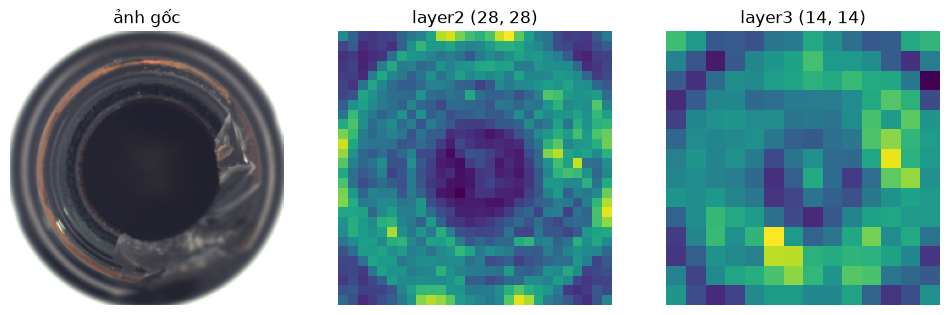

In [2]:
import matplotlib.pyplot as plt

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def denorm(img):
    """Đảo phép Normalize để vẽ lại ảnh bình thường."""
    return (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(denorm(image))
axes[0].set_title("ảnh gốc")
for ax, name in zip(axes[1:], ["layer2", "layer3"]):
    fmap = feats[name][0].mean(dim=0)        # (h, w): trung bình qua các kênh
    ax.imshow(fmap.numpy(), cmap="viridis")
    ax.set_title(f"{name} {tuple(fmap.shape)}")
for ax in axes:
    ax.axis("off")
plt.show()